## Imports

In [1]:
import os

for _k, _v in (
    ("OMP_NUM_THREADS", "1"),
    ("MKL_NUM_THREADS", "1"),
    ("OPENBLAS_NUM_THREADS", "1"),
    ("NUMEXPR_NUM_THREADS", "1"),
    ("VECLIB_MAXIMUM_THREADS", "1"),
):
    os.environ.setdefault(_k, _v)

import numpy as np
import scipy

print("NumPy:", np.__version__)
print("SciPy:", scipy.__version__)
print("OK — core stack. Run sections below in order.")


NumPy: 2.4.2
SciPy: 1.17.1
OK — core stack. Run sections below in order.


If the kernel still dies, it is usually a **native extension** issue on **Python 3.13** (PyTorch / OpenCV / FAISS wheels). Create a venv with **Python 3.11 or 3.12**, reinstall `requirements.txt`, and retry. Run cells **in order** so thread limits apply before FAISS loads.


## Pytorch

In [2]:
import torch

# Create a 2x3 tensor filled with ones
tensor = torch.ones((2, 3))
print("Tensor:\n", tensor)

# Perform a basic operation: addition
tensor_add = tensor + 2
print("After addition:\n", tensor_add)

print("PyTorch:", torch.__version__)


Tensor:
 tensor([[1., 1., 1.],
        [1., 1., 1.]])
After addition:
 tensor([[3., 3., 3.],
        [3., 3., 3.]])
PyTorch: 2.10.0


## Numpy

In [3]:
# Create a 1D array of integers from 0 to 4
array = np.arange(5)
print("Array:", array)

# Compute the mean of the array
mean_value = np.mean(array)
print("Mean value:", mean_value)


Array: [0 1 2 3 4]
Mean value: 2.0


## Scipy

In [4]:
from scipy.linalg import solve

# Coefficient matrix (float64 avoids dtype edge cases)
A = np.array([[3.0, 2.0], [1.0, 4.0]], dtype=np.float64)
# Right-hand side
b = np.array([6.0, 8.0], dtype=np.float64)

# Solve the linear system A x = b
x = solve(A, b)
print("Solution:", x)

Solution: [0.8 1.8]


## Matplotlib

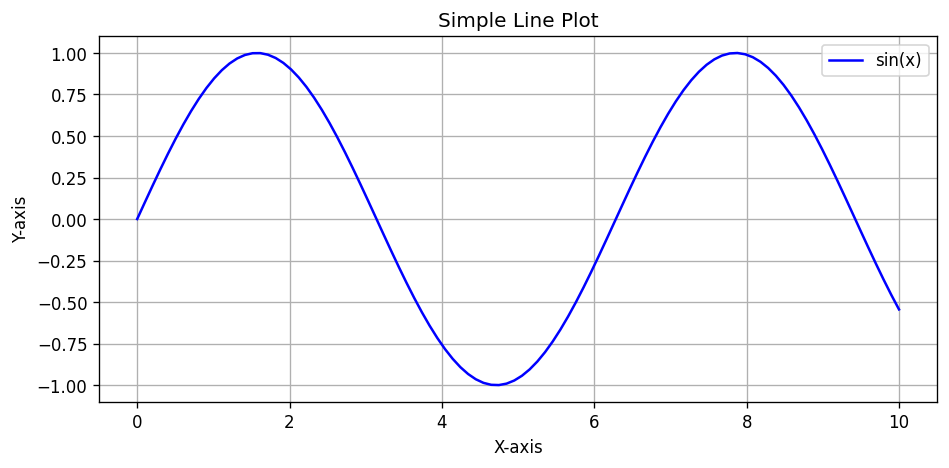

In [5]:
import matplotlib

# Non-GUI backend — avoids hard kernel crashes with Cursor/Jupyter on macOS (esp. Python 3.13)
matplotlib.use("Agg")

from io import BytesIO
from matplotlib import pyplot as plt
from IPython.display import Image, display

# Generate data
x = np.linspace(0, 10, 100)
y = np.sin(x)

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(x, y, label='sin(x)', color='blue', linestyle='-')
ax.set_title('Simple Line Plot')
ax.set_xlabel('X-axis')
ax.set_ylabel('Y-axis')
ax.legend()
ax.grid(True)
fig.tight_layout()

buf = BytesIO()
fig.savefig(buf, format="png", bbox_inches="tight", dpi=120)
plt.close(fig)
display(Image(data=buf.getvalue(), format="png"))


## OpenCV

Load with **`cv2`**, render with matplotlib **Agg** to a **PNG** and **`IPython.display.Image`** so you see a real image in the output—**not** the `<Figure …>` text repr.


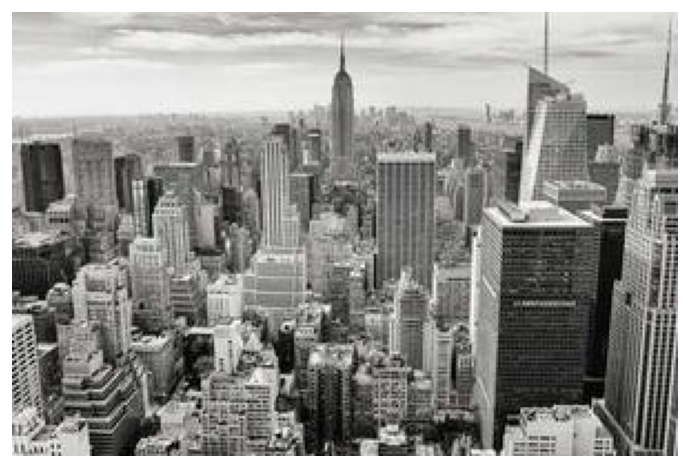

In [6]:
import numpy as np
import cv2
from pathlib import Path
from io import BytesIO

import matplotlib
matplotlib.use("Agg")

from matplotlib import pyplot as plt
from IPython.display import Image, display

img_path = Path("../mini-dataset/test_img.jpg")
if img_path.is_file():
    image = cv2.imread(str(img_path))
else:
    image = None

if image is None:
    image_rgb = np.zeros((120, 160, 3), dtype=np.uint8)
    image_rgb[:, :] = (40, 80, 160)
else:
    image_rgb = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

fig, ax = plt.subplots(figsize=(6, 4))
ax.imshow(image_rgb)
ax.set_axis_off()
fig.tight_layout()

buf = BytesIO()
fig.savefig(buf, format="png", bbox_inches="tight", dpi=120)
plt.close(fig)
display(Image(data=buf.getvalue(), format="png"))

## Nearest neighbors (NumPy, not FAISS)

The real index in this repo uses **`faiss-cpu`** (native C++). **`import faiss` in Jupyter often crashes the kernel** on macOS (especially with Python 3.13), so this demo uses **NumPy** to match **IndexFlatL2** behavior: squared L2 distance, brute-force top‑k.


In [7]:
# Same idea as faiss.IndexFlatL2 + search: squared L2, k=2 nearest rows
data = np.random.default_rng(0).random((10, 3)).astype(np.float32)
query = np.random.default_rng(1).random((1, 3)).astype(np.float32)

d2 = np.sum((data - query) ** 2, axis=1)  # squared L2 to each row
k = 2
order = np.argsort(d2)[:k]
indices = order.reshape(1, -1)
distances = d2[order].reshape(1, -1).astype(np.float32)

print("Query vector:", query)
print("Nearest neighbors' indices:", indices)
print("Distances (squared L2, like FAISS):", distances)


Query vector: [[0.5118216  0.9504637  0.14415962]]
Nearest neighbors' indices: [[3 2]]
Distances (squared L2, like FAISS): [[0.21726108 0.2173888 ]]
